# Shell sort

Generaliza la inserción: primero ordena por inserción los elementos separados por un salto $h$ grande y va reduciendo $h$ hasta 1. Los saltos grandes mueven rápido los elementos lejanos, así que la última pasada ($h = 1$, inserción normal) encuentra la lista casi ordenada. El coste depende de la secuencia de saltos: $O(n^2)$ con $n/2, n/4, \dots$ (Shell) y alrededor de $O(n^{4/3})$ con la de Sedgewick o la de Ciura. Ordena in situ y no es estable.

## 1. Shell sort con los saltos de Shell

Implementar shell sort con la secuencia $\lfloor n/2 \rfloor, \lfloor n/4 \rfloor, \dots, 1$ y comprobarlo contra `sorted` con listas aleatorias.

In [1]:
import random
import time

import matplotlib.pyplot as plt

def shell_sort(lista, saltos=None):
    l = lista[:]
    n = len(l)
    if saltos is None:
        saltos = []
        h = n // 2
        while h > 0:
            saltos.append(h)
            h //= 2
    for h in saltos:
        for i in range(h, n):
            valor, j = l[i], i
            while j >= h and l[j - h] > valor:
                l[j] = l[j - h]
                j -= h
            l[j] = valor
    return l

random.seed(1)
for _ in range(500):
    datos = [random.randint(-50, 50) for _ in range(random.randint(0, 40))]
    assert shell_sort(datos) == sorted(datos)
print(shell_sort([35, 33, 42, 10, 14, 19, 27, 44, 26, 31]))

[10, 14, 19, 26, 27, 31, 33, 35, 42, 44]


## 2. Traza de las pasadas

Mostrar la lista tras cada salto para ver cómo cada pasada deja ordenadas por inserción las sublistas de elementos separados $h$ posiciones.

In [2]:
def shell_sort_traza(lista):
    l = lista[:]
    h = len(l) // 2
    while h > 0:
        for i in range(h, len(l)):
            valor, j = l[i], i
            while j >= h and l[j - h] > valor:
                l[j] = l[j - h]
                j -= h
            l[j] = valor
        print(f"h = {h}: {l}")
        assert all(l[k] <= l[k + h] for k in range(len(l) - h))  # queda h-ordenada
        h //= 2
    return l

shell_sort_traza([62, 83, 18, 53, 7, 17, 95, 86, 47, 69, 25, 28])

h = 6: [62, 83, 18, 53, 7, 17, 95, 86, 47, 69, 25, 28]
h = 3: [53, 7, 17, 62, 25, 18, 69, 83, 28, 95, 86, 47]
h = 1: [7, 17, 18, 25, 28, 47, 53, 62, 69, 83, 86, 95]


[7, 17, 18, 25, 28, 47, 53, 62, 69, 83, 86, 95]

## 3. Comparar secuencias de saltos

Contar las comparaciones de shell sort con las secuencias de Shell ($n/2^k$), Knuth ($1, 4, 13, 40, \dots$, $h_{k+1} = 3h_k + 1$) y Ciura ($1, 4, 10, 23, 57, 132, 301, 701$, ampliada con $\times 2.25$) frente a la inserción simple, para listas aleatorias de distintos tamaños.

inserción  [2755, 19574, 261593, 2216708]
Shell      [911, 3418, 14987, 56445]
Knuth      [733, 3083, 13444, 54389]
Ciura      [739, 2981, 13042, 48051]


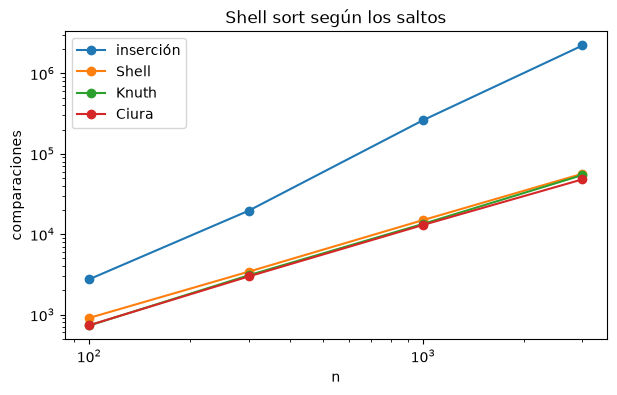

In [3]:
def shell_contando(lista, saltos):
    l, comparaciones = lista[:], 0
    for h in saltos:
        for i in range(h, len(l)):
            valor, j = l[i], i
            while j >= h:
                comparaciones += 1
                if l[j - h] <= valor:
                    break
                l[j] = l[j - h]
                j -= h
            l[j] = valor
    assert l == sorted(lista)
    return comparaciones

def saltos_shell(n):
    h, s = n // 2, []
    while h > 0:
        s.append(h)
        h //= 2
    return s

def saltos_knuth(n):
    h, s = 1, []
    while h < n:
        s.append(h)
        h = 3 * h + 1
    return s[::-1]

def saltos_ciura(n):
    s = [1, 4, 10, 23, 57, 132, 301, 701]
    while s[-1] < n:
        s.append(int(s[-1] * 2.25))
    return [h for h in s if h < n][::-1] or [1]

tamanos = [100, 300, 1000, 3000]
secuencias = {"inserción": lambda n: [1], "Shell": saltos_shell, "Knuth": saltos_knuth, "Ciura": saltos_ciura}
random.seed(2)
resultados = {nombre: [] for nombre in secuencias}
for n in tamanos:
    datos = random.sample(range(n), n)
    for nombre, saltos in secuencias.items():
        resultados[nombre].append(shell_contando(datos, saltos(n)))

for nombre, valores in resultados.items():
    print(f"{nombre:<10}", valores)

fig, eje = plt.subplots(figsize=(7, 4))
for nombre, valores in resultados.items():
    eje.plot(tamanos, valores, "o-", label=nombre)
eje.set(xscale="log", yscale="log", xlabel="n", ylabel="comparaciones", title="Shell sort según los saltos")
eje.legend()
plt.show()

## 4. No es estable

Mostrar con un ejemplo que shell sort no es estable: ordenar por nota una lista de alumnos y ver que dos con la misma nota cambian de orden, al contrario que con `sorted`.

In [4]:
def shell_sort_clave(lista, clave):
    l, h = lista[:], len(lista) // 2
    while h > 0:
        for i in range(h, len(l)):
            valor, j = l[i], i
            while j >= h and clave(l[j - h]) > clave(valor):
                l[j] = l[j - h]
                j -= h
            l[j] = valor
        h //= 2
    return l

alumnos = [("Ana", 7), ("Luis", 9), ("Eva", 5), ("Pau", 7), ("Noa", 5), ("Iker", 3)]
nota = lambda a: a[1]
print("shell sort:", shell_sort_clave(alumnos, nota))
print("sorted:    ", sorted(alumnos, key=nota))
assert shell_sort_clave(alumnos, nota) != sorted(alumnos, key=nota)

shell sort: [('Iker', 3), ('Noa', 5), ('Eva', 5), ('Ana', 7), ('Pau', 7), ('Luis', 9)]
sorted:     [('Iker', 3), ('Eva', 5), ('Noa', 5), ('Ana', 7), ('Pau', 7), ('Luis', 9)]
